In [1]:
import numpy as np

In [2]:
x = np.array([ 56755.72171242,  44178.04737774,  40991.80813814,   8814.00098681, 43585.51198178,  13574.17183072,   6175.8760297 ,  17829.69832237, 53254.85637009,  17522.23018625,  42784.69836164,  36638.18492916, 41086.72967373,  18167.77372717,  12706.89121489,  52564.42917946, 61995.42280258,  35776.79516181,  30230.22630213,  34524.46986093, 13774.60527391,  14258.22933451, 101376.49657434,   9616.64500569, 45175.23189338,  38615.99518491,  74355.51585756,  12578.49547344, 19242.3664711 ,  16310.988409  ,  20881.76692993,   5734.63362915, 25732.01836475,  51545.48360953,  82081.59716162,  11006.2497364 , 44974.83187718,  56839.38177423])

In [3]:
y = np.array([7.3, 7.1, 6.9, 6.4, 7.4, 6.5, 6.3, 6.7, 7.6, 5.7, 7.6, 6.5, 7.0, 5.4, 5.6, 7.5, 7.0, 7.2, 6.0, 5.9, 5.9, 5.9, 6.9, 6.5, 7.4, 7.3, 7.6, 6.1, 5.4, 6.2, 5.9, 4.7, 6.3, 7.3, 7.5, 5.5, 6.8, 6.9])

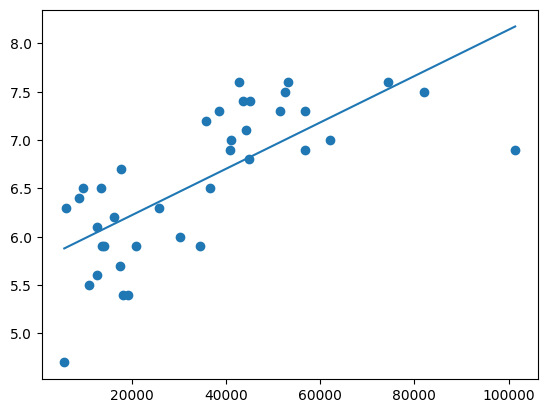

In [4]:
import matplotlib.pyplot as plt
p = np.poly1d(np.polyfit(x, y, 1))
x_line = np.linspace(np.amin(x), np.amax(x), 200)
plt.scatter(x, y)
plt.plot(x_line, p(x_line))
plt.show()

In [5]:
print(p)

 
2.4e-05 x + 5.742


In [6]:
from scipy import stats
regr_results = stats.linregress(x, y)
print(regr_results)

LinregressResult(slope=np.float64(2.3996299825729513e-05), intercept=np.float64(5.741754353755326), rvalue=np.float64(0.720287195322656), pvalue=np.float64(3.4265564700646986e-07), stderr=np.float64(3.851624914535862e-06), intercept_stderr=np.float64(0.15853194959552008))


In [7]:
import statsmodels.api as sm

x_const = sm.add_constant(x)  # Adds intercept (x itself stays 1D)
lin_model = sm.OLS(y, x_const)
regr_results = lin_model.fit()

print(regr_results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.519
Model:                            OLS   Adj. R-squared:                  0.505
Method:                 Least Squares   F-statistic:                     38.82
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           3.43e-07
Time:                        17:50:29   Log-Likelihood:                -28.824
No. Observations:                  38   AIC:                             61.65
Df Residuals:                      36   BIC:                             64.92
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.7418      0.159     36.218      0.0

In [8]:
from sklearn import linear_model
linmodel = linear_model.LinearRegression(fit_intercept=True)
linmodel.fit(x.reshape(-1, 1), y)

LinearRegression()

In [9]:
(slope, intercept) = (linmodel.coef_[0], linmodel.intercept_)
print(slope, intercept)

2.3996299825729496e-05 5.741754353755327


In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

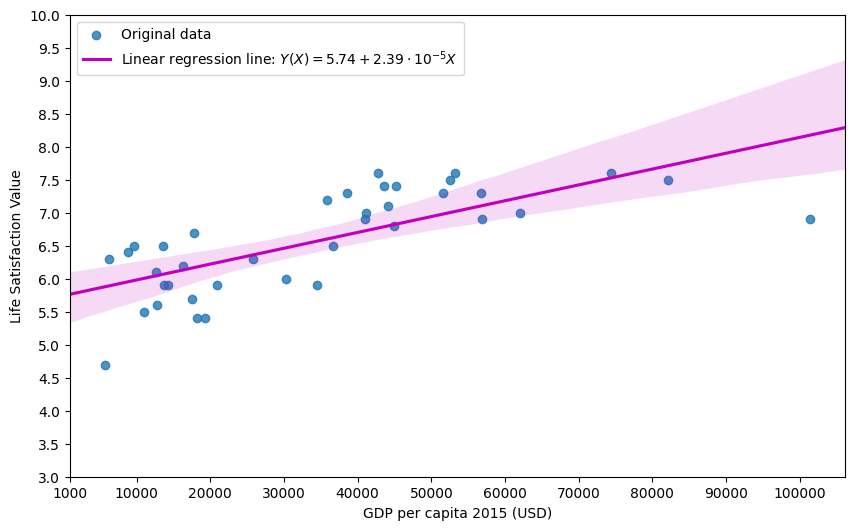

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(x=x, y=y, ci=95, order=1, ax=ax,
            line_kws={'label': r'Linear regression line: $Y(X)=5.74+2.39\cdot 10^{-5} X$', 'color': 'm'},
            seed=1, truncate=False, label="Original data")
ax.set_xlabel("GDP per capita 2015 (USD)")
ax.set_ylabel("Life Satisfaction Value")
ax.set_xticks([1000, 10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000, 100000])
ax.set_yticks(np.arange(3.0, 10.5, 0.5))
ax.legend(loc="upper left")
plt.show()